In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import re
import pandas as pd
from io import StringIO
import numpy as np

In [12]:
with open("../backup.sql", "r") as f:
    sql = f.read()

# Extraer el bloque COPY de run_results
match = re.search(
    r"COPY public\.run_results \((.+?)\) FROM stdin;\n(.*?)\\\.",
    sql,
    re.DOTALL,
)

columns = [c.strip() for c in match.group(1).split(",")]
data = match.group(2)

df = pd.read_csv(StringIO(data), sep="\t", names=columns, na_values=["\\N"])

def filter_by_experiment_prefix(df: pd.DataFrame, prefix: str, column: str = "experiment_id") -> pd.DataFrame:
    return df[df[column].str.startswith(prefix)].copy()

def prepare_dataframe(df: pd.DataFrame):
    df = df.copy()

    def extract_C(text):
        match = re.search(r'C(\d+)', text)
        return float(match.group(1)) if match else None

    def extract_V(text):
        match = re.search(r'V(\d+)', text)
        return float(match.group(1)) if match else None

    def extract_size(c):
        if 0 < c <= 25:
            return "small"
        elif 25 < c <= 50:
            return "medium"
        elif 50 < c <= 80:
            return "big"
        else:
            return "large"

    df["c"] = df["experiment_id"].apply(extract_C)
    df["v"] = df["experiment_id"].apply(extract_V)
    df["size"] = df["c"].apply(extract_size)

    c, v, n = df["c"], df["v"], (df["c"] + 2*df["v"])     
    df['dim'] = (2*c*v*n) + (3*(n**2)*v) + (2*v*c) + v
    return df

df = prepare_dataframe(filter_by_experiment_prefix(df=df, prefix="turing"))

<Axes: >

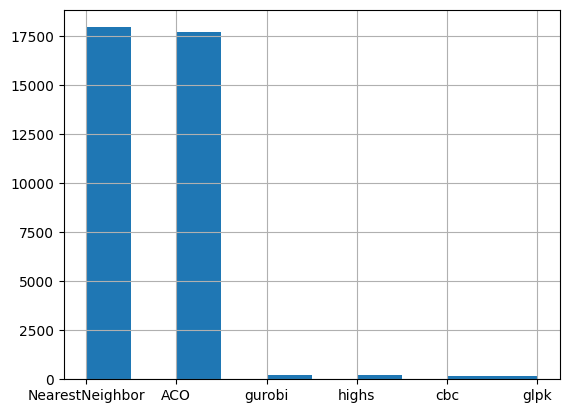

In [13]:
df['solver'].hist()

Comencemos viendo los porcentajes de feasibilidad de cada solver. 
Luego la siguiente pregunta que nos viene es: como sabemos que las soluciones de los solvers son realmente feasibles ? Para ello esta la columna *valid* el cual cheque manualmente si la ruta resultante es valida o no, chequeando cada restriccion. De esta forma podemos asegurar que las soluciones son correctas.

In [14]:
df['solver'].unique()

array(['NearestNeighbor', 'ACO', 'gurobi', 'highs', 'cbc', 'glpk'],
      dtype=object)

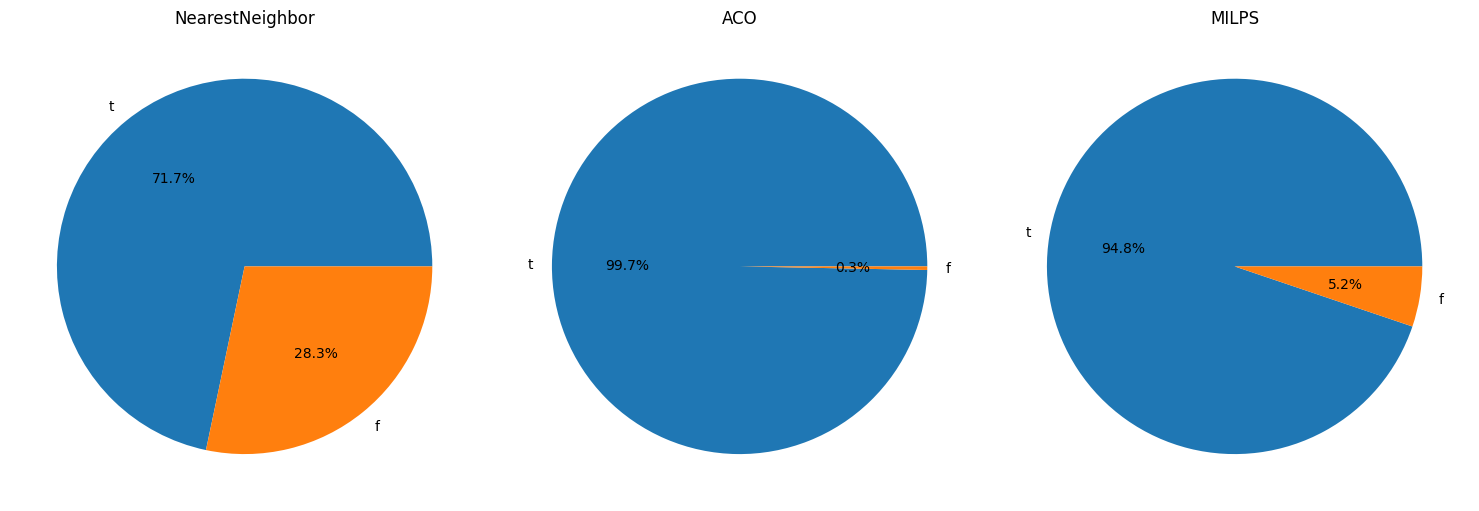

In [15]:
solvers = ["NearestNeighbor", "ACO"]
groups = {s: df[df["solver"] == s] for s in solvers}
groups["MILPS"] = df[~df["solver"].isin(solvers)]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, group) in zip(axes, groups.items()):
    counts = group["feasible"].value_counts()
    ax.pie(counts, labels=counts.index, autopct="%1.1f%%")
    ax.set_title(name)

plt.tight_layout()
plt.show()

Aca aparece algo raro, porque milp esta fallando siempre en la misma condicion. Le este errando a una ventana de tiempo, es decir que la solucion de un $li~$(estimado) > $li$(verdadero). 
Al principio pense que era un bug de un solver en particular, pero que todos se hayan equivocado en el mismo como muestra el segundo grafico, quiere decir que estamos generado mal las instancias (debe ser un caso particular pero un bug que debemos arreglar)

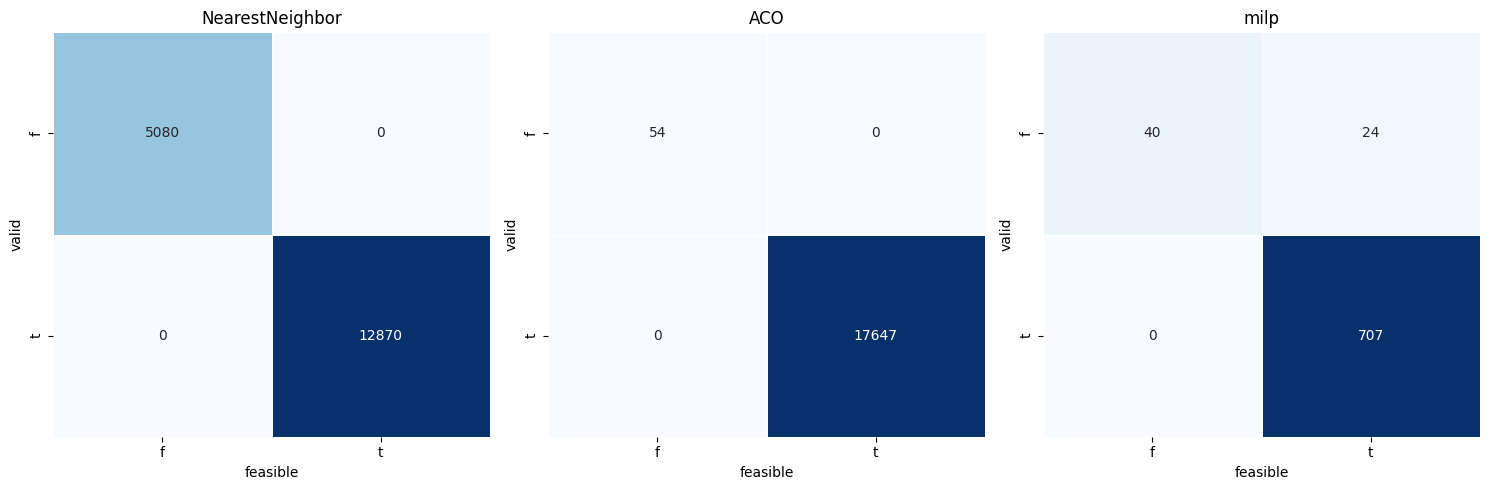

In [16]:
milp_solvers = ["gurobi", "highs", "cbc", "glpk"]
solvers = ["NearestNeighbor", "ACO"]

groups = {s: df[df["solver"] == s] for s in solvers}
groups["milp"] = df[df["solver"].isin(milp_solvers)]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, group) in zip(axes, groups.items()):
    matrix = pd.crosstab(group["valid"], group["feasible"])
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        linewidths=0.5,
        linecolor="white",
        ax=ax,
        cbar=False,
    )
    ax.set_title(name)
    ax.set_xlabel("feasible")
    ax.set_ylabel("valid")

plt.tight_layout()
plt.show()

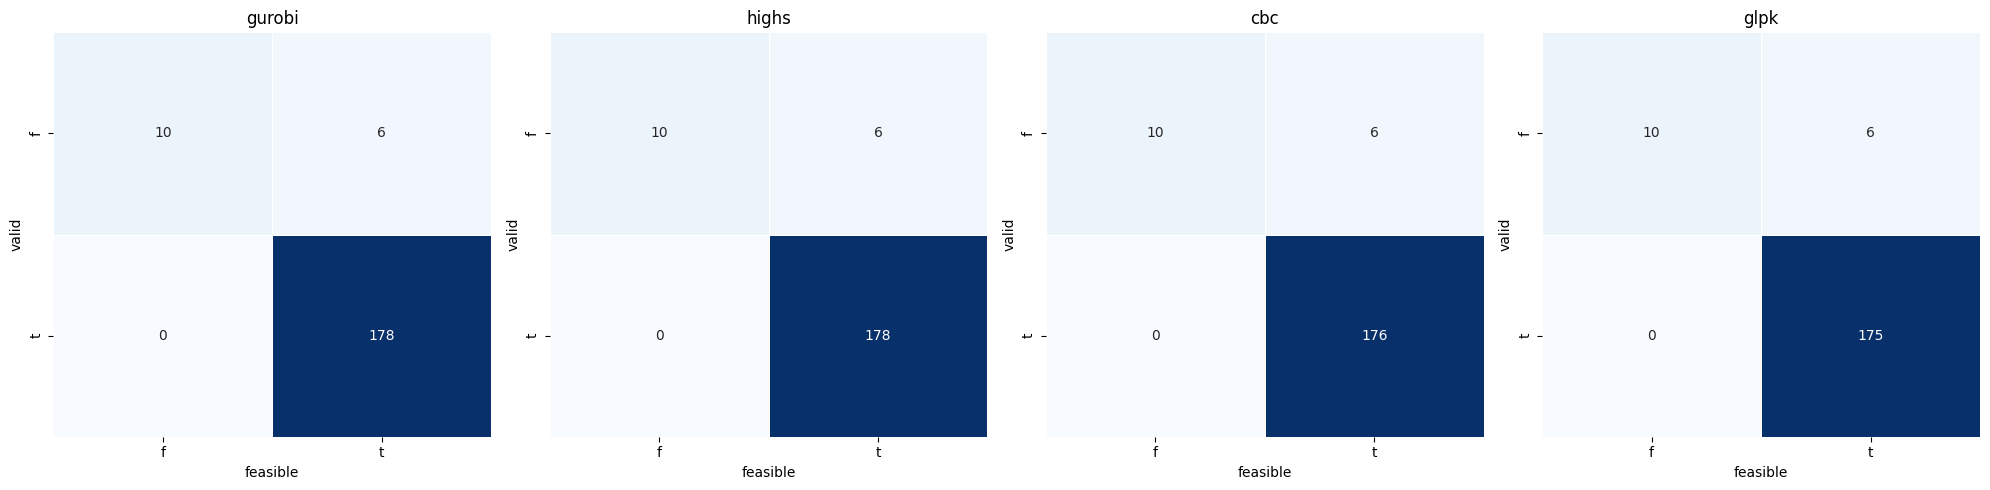

In [17]:
fig, axes = plt.subplots(1, len(milp_solvers), figsize=(5 * len(milp_solvers), 5))

for ax, solver in zip(axes, milp_solvers):
    group = df[df["solver"] == solver]
    matrix = pd.crosstab(group["valid"], group["feasible"])
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        linewidths=0.5,
        linecolor="white",
        ax=ax,
        cbar=False,
    )
    ax.set_title(solver)
    ax.set_xlabel("feasible")
    ax.set_ylabel("valid")

plt.tight_layout()
plt.show()

---

### INICIO CORRECION BUG

Intentemos de entender que esta pasando con los solvers milps. Que tengamos intancias invalidas quiere decir que estamos generando mal las intancias, y entender porque no sucede con los otros solvers. Capaz milp lleva tan al limite con el fin de minimizar y los otros no.

Aparentemente la mayor proporcion de errores se da cuando hay mas vehiuclos que customers. Agrupemos y vemos cual es la convinacion que genera mas errores y generemos esas instancias para poder entender un poco mas el problema.

Bueno tenemos algo, todas las intancias c=5 y v=18 fueron invalidas! asique generemos esas.

In [18]:
# err_df = df[(df['feasible'] == 't') & (df['solver'].isin(milp_solvers)) & (df['valid'] == 'f')]
# err_df.hist(['c', 'v'])
# print(f'cantidad de instancias erroneas: {err_df.count()}')

In [19]:
# err_df[err_df['c'] < err_df['v']].count()
# err_df.groupby(['c', 'v']).size().sort_values(ascending=False)
# df[(df['solver'].isin(milp_solvers)) & (df['c'] == 5) & (df['v'] == 18)].groupby(['valid', 'feasible']).size()

In [20]:
# import sys
# sys.path.insert(0, '..')

# from data.generators.synthetic import SyntheticGenerator
# from solvers.milp2a1 import MILPSolver
# from validators.solution_validator import SolutionChecker

# cfg_experiment = {
#     'num_customers': 5,
#     'num_vehicles': 18,
#     'capacity': [100],
#     'vehicle_penalty': 0,
#     'customer_demand': 1,
#     'seed': 42,
# }

# cfg_generator = {
#     'cost_range': 'low',
#     'tw_tightness': 'loose',
#     'matrix_costs_ranges': {'low': [1, 20], 'high': [100, 200], 'high_dispersion': [1, 300]},
#     'time_windows_tightness': {'loose': [0, 500], 'tight': [0, 20], 'critical': [0, 7]},
#     'time_windows_values': [5, 10],
# }
# solver = MILPSolver(cfg_milp={'solver': 'highs'})
# gen = SyntheticGenerator(cfg_experiment=cfg_experiment, cfg_generator=cfg_generator)

# valid = True
# while valid:
#     instance = gen.generate()
#     solution = solver.solve(instance)

#     print(f"{solution}")

#     if solution.feasible:
#         checker = SolutionChecker(insta=instance)
#         valid = checker.check(solution.routes, solver.get_solver_name())
#         print(f"valid:    {valid}")
#     else:
#         print("solver marcó infeasible, nada para chequear")

### BUG CORREGIDO: cfb499a7c88f31248f8457db6ac70d6d8f4135b8
--- 

Para cada simulacion, los posibles estados de las ejecuciones son: finished, error, timeout. Veamos que distribucion tienen

<Axes: >

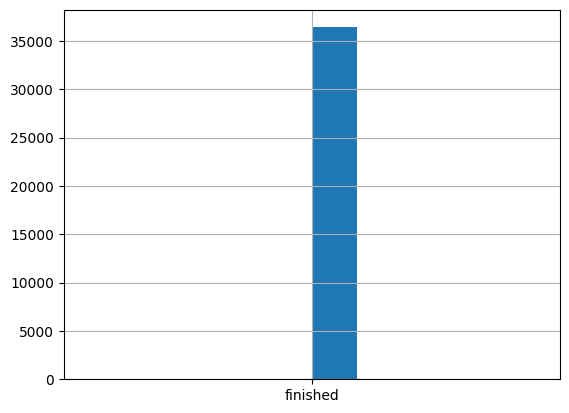

In [21]:
df['status'].hist()

In [22]:
df = df[df['valid'] == 't']
df = df[df['status'] == 'finished']

Ahora que nos aseguramos que para todos los solvers terminaron y que todas las soluciones son correctas, podemos hacer un analisis de las disntas soluciones de cada solver porque estamos comparando cosas equivalentes. Cosa que no pasaria si compararamos el runtime de una solucion con status timeout y otra con estatus finished.

Como se muestra en el histograma de abajo, no tenemos tantas intancias de milp para dimensiones grandes por el tiempo de computo que consumen. Pero tenemos una buena fromula cerrada para estimar el runtime. Es mas, el timeout para cada simulacion se establece por esta formula y dado que una llegamos a un timeout nos desmuestra lo acertada que es.

$$0.002 * (c ^ (0.00023)) * (v ^ (2.41))$$


Despues de analizar, esto estima segun el v y c pero creo que una mejor cota es por dimension, por la forma que tiene en el grafico

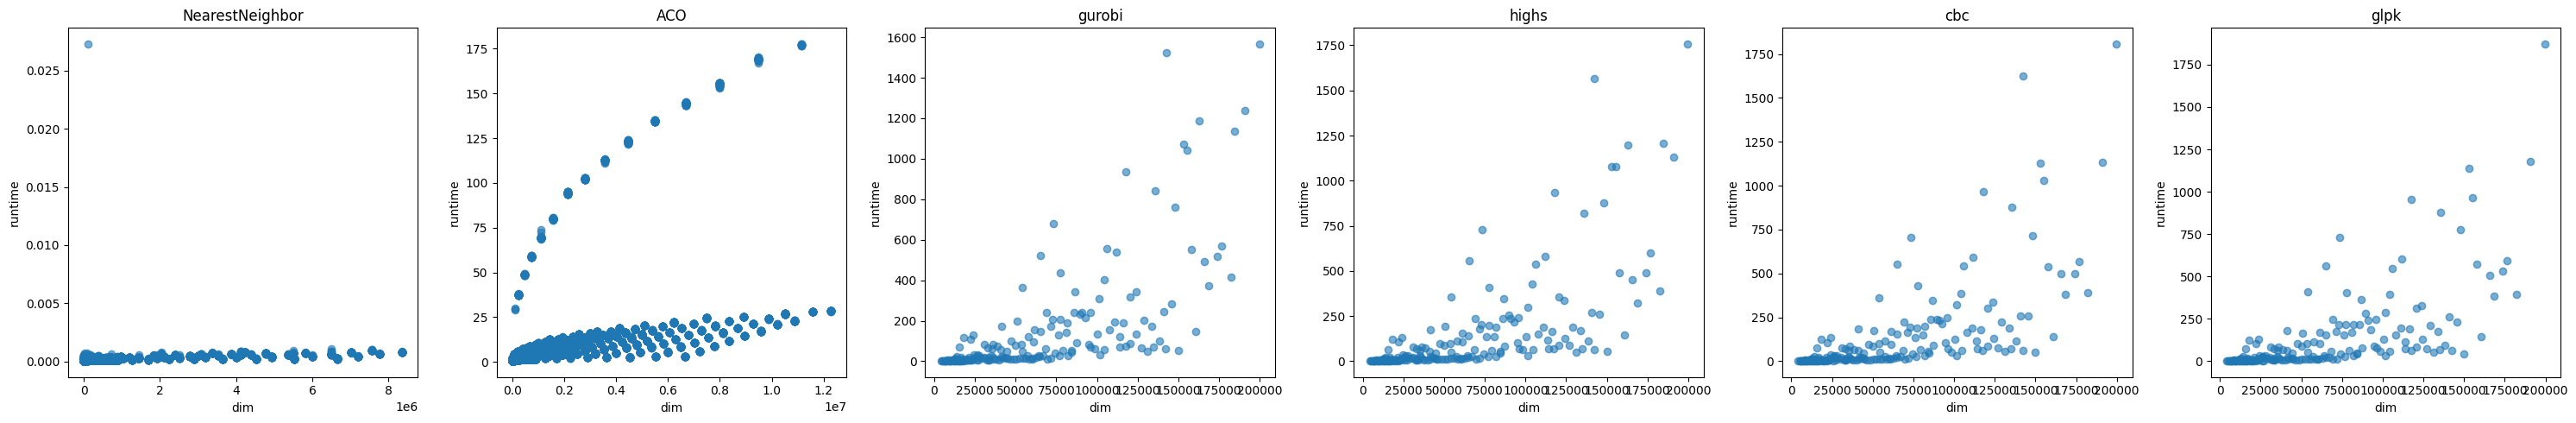

In [23]:
all_solvers = df["solver"].unique()
n = len(all_solvers)

fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))

for ax, solver in zip(axes, all_solvers):
    group = df[df["solver"] == solver]
    ax.scatter(group["dim"], group["runtime"], alpha=0.6)
    ax.set_title(solver)
    ax.set_xlabel("dim")
    ax.set_ylabel("runtime")

plt.tight_layout()
plt.show()

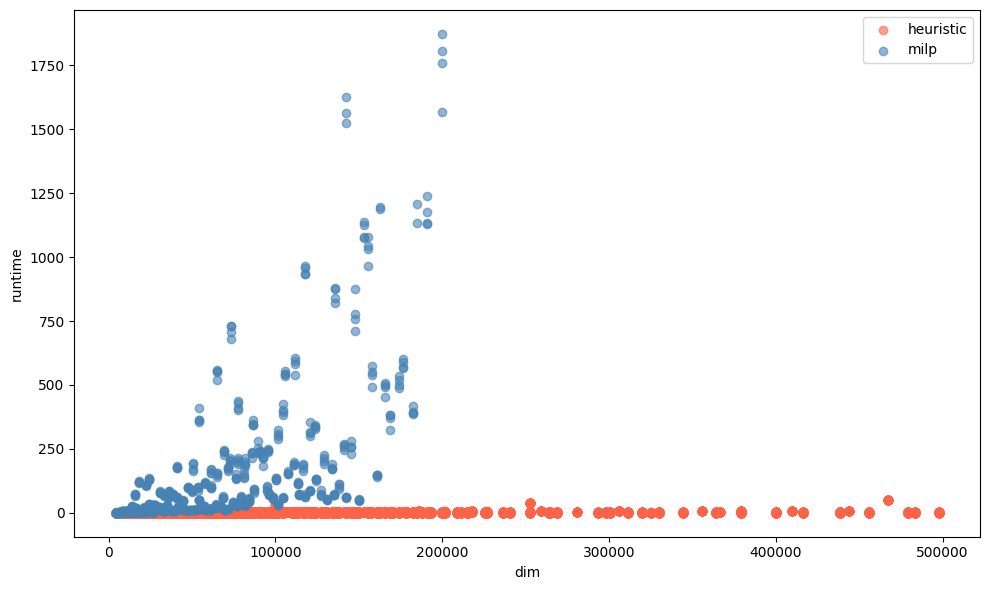

In [24]:
threshold = 0.5*1e6 # porque milp no tiene simulaciones para grandes dimenciones
fig, ax = plt.subplots(figsize=(10, 6))

for solver in all_solvers:
    group = df[(df["solver"] == solver) & (df['dim'] < threshold)]
    if solver in milp_solvers:
        color = "steelblue"
        label = "milp"
    else:
        color = "tomato"
        label = "heuristic"
    ax.scatter(group["dim"], group["runtime"], color=color, label=label, alpha=0.6)

# Evitar duplicados en la leyenda
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))


ax.legend(by_label.values(), by_label.keys())
ax.set_xlabel("dim")
ax.set_ylabel("runtime")


plt.tight_layout()
plt.show()

/var/folders/qs/fs8lbvfj3_b27ftnbgv_842c0000gn/T/ipykernel_58166/4191413214.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_f["runtime_est"] = 0.002 * (df_f['c'] ** 2.59) * (df_f['v'] ** 2.41)


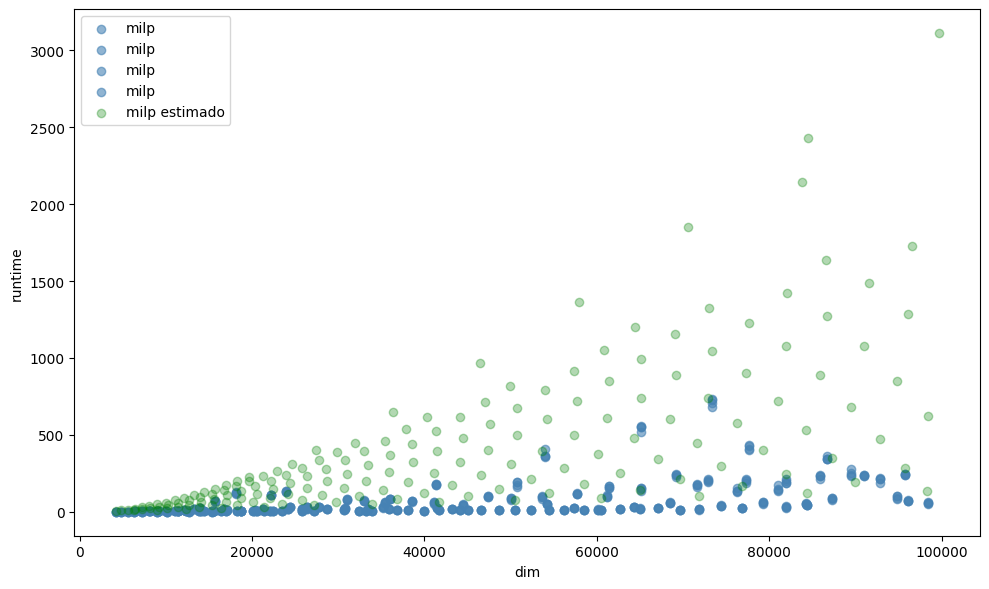

In [25]:
threshold = 0.1*1e6 # porque milp no tiene simulaciones para grandes dimenciones

df_f = df[df['dim'] < threshold]

fig, ax = plt.subplots(figsize=(10, 6))

for solver in milp_solvers:
    group = df[(df["solver"] == solver) & (df['dim'] < threshold)]
    if solver in milp_solvers:
        color = "steelblue"
        label = "milp"
    else:
        color = "tomato"
        label = "heuristic"
    ax.scatter(group["dim"], group["runtime"], color=color, label=label, alpha=0.6)

# Evitar duplicados en la leyenda
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))

# Estimacion del runtime
df_f["runtime_est"] = 0.002 * (df_f['c'] ** 2.59) * (df_f['v'] ** 2.41)
max_est = df_f.groupby("dim")["runtime_est"].max().reset_index()
ax.scatter(max_est["dim"], max_est["runtime_est"], color="green", label="milp estimado", alpha=0.3)

plt.ylabel("runtime")
plt.xlabel("dim")
plt.legend()
plt.tight_layout()
plt.show()

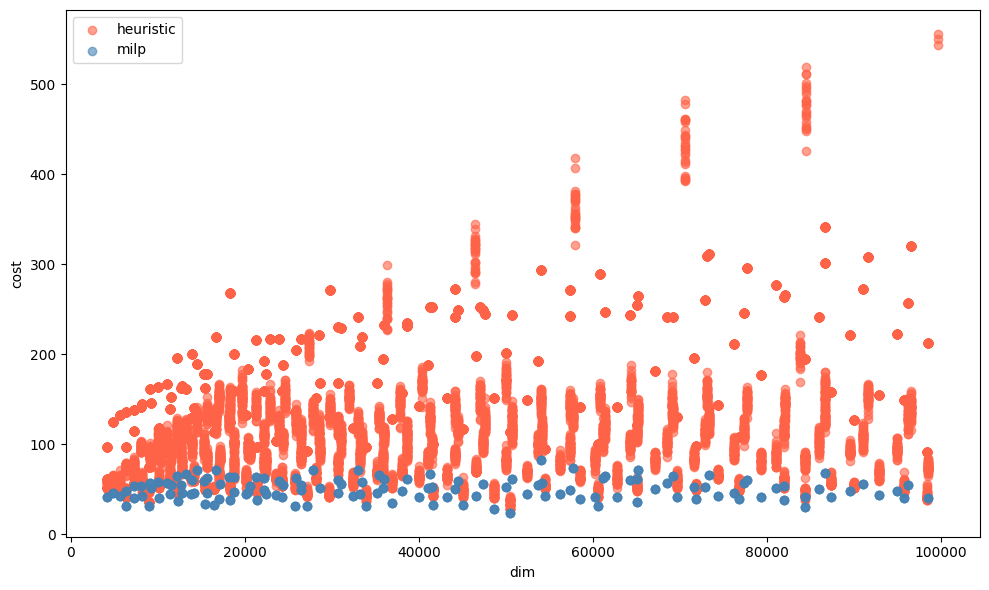

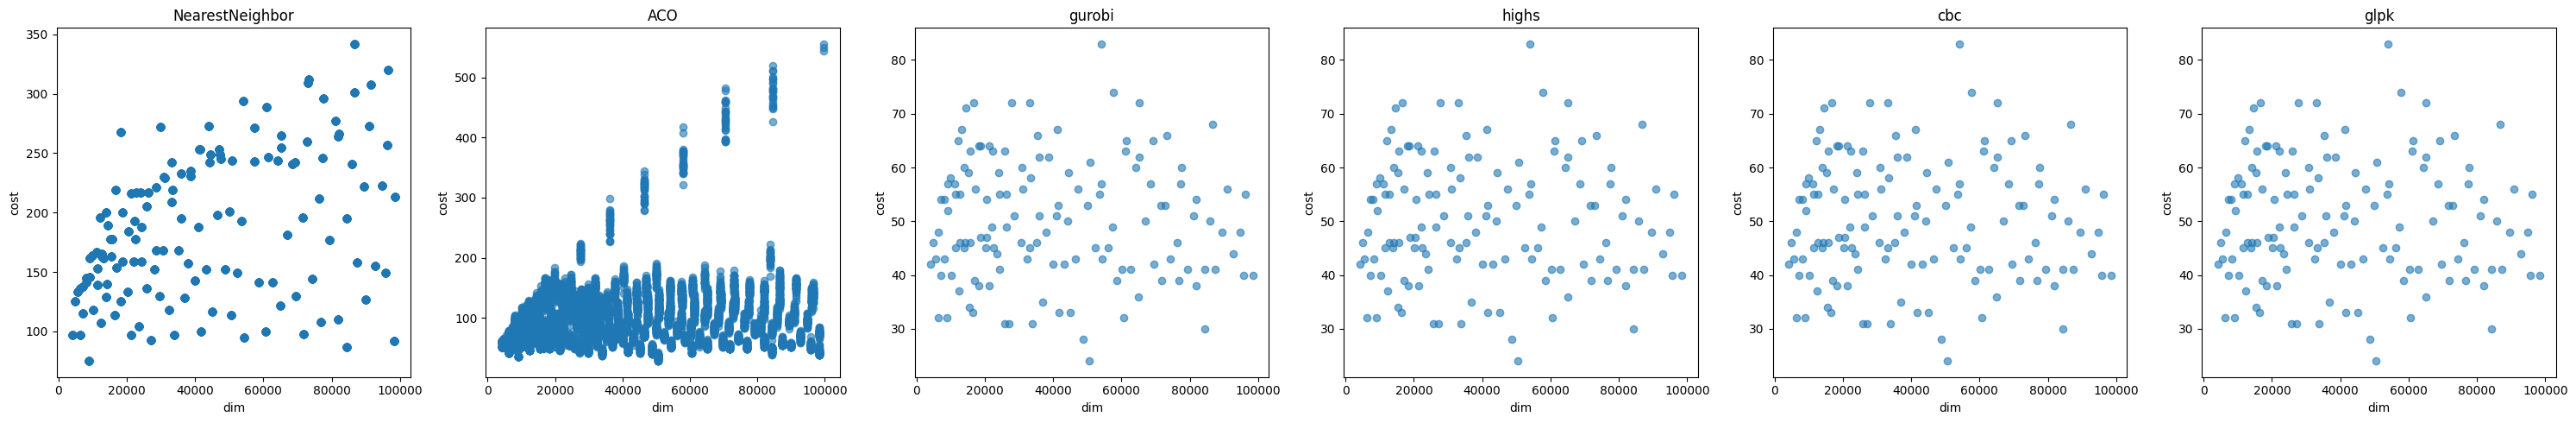

In [26]:
cost_threshold = 100000
# Grafico combinado
fig, ax = plt.subplots(figsize=(10, 6))

for solver in df["solver"].unique():
    group = df[(df["solver"] == solver) & (df["dim"] < threshold)]
    color = "steelblue" if solver in milp_solvers else "tomato"
    label = "milp" if solver in milp_solvers else "heuristic"
    ax.scatter(group["dim"], group["cost"], color=color, label=label, alpha=0.6)

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))

ax.legend(by_label.values(), by_label.keys())
ax.set_xlabel("dim")
ax.set_ylabel("cost")
plt.tight_layout()
plt.show()

# Grafico por solver
solvers = df["solver"].unique()
n = len(solvers)

fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))

for ax, solver in zip(axes, solvers):
    group = df[(df["solver"] == solver) & (df["dim"] < threshold)]
    ax.scatter(group["dim"], group["cost"], alpha=0.6)
    ax.set_title(solver)
    ax.set_xlabel("dim")
    ax.set_ylabel("cost")


plt.tight_layout()
plt.show()

Tal como vemos en las imagenes previas, hay una clara diferencia entre solvers milp y solvers estocasticos como aco o nn en cuanto a costo. Pero no podemos obviar el tiempo exponencial que parece necesitar estos algoritmos, mientras que los estocasticos mentienen tiempos lineales/constantes.
Si bien todos los solvers milp tienen runtime similares y costos similares cabe destacar que gurobi lo usamos con una licencia de estudiante, pero por este solver deberiamos pagar, lo que nos dice que usando uno opensource podemos obtener los mismo resultados sin tener que comprar la suscripción

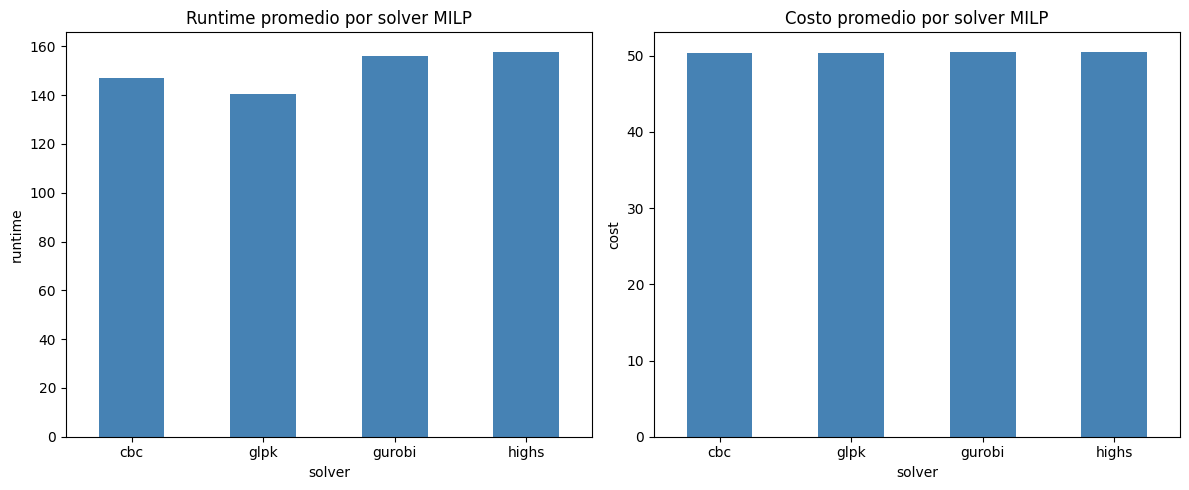

In [27]:
milp_df = df[df["solver"].isin(milp_solvers)]
stats = milp_df.groupby("solver")[["runtime", "cost"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

stats["runtime"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Runtime promedio por solver MILP")
axes[0].set_xlabel("solver")
axes[0].set_ylabel("runtime")
axes[0].tick_params(axis="x", rotation=0)

stats["cost"].plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Costo promedio por solver MILP")
axes[1].set_xlabel("solver")
axes[1].set_ylabel("cost")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

En cuanto a la comparacion milp vs stocastic (fijamos un c y un v aleatorio) seria interesante ver a que soluciones llegan NN y ACO si le demos un x2,x3 del tiempo que usaron para encontrar la solucion, y para el mismo tiempo que utilizo milp ? porque como podemos ver en el grafico de los costos de aco los valores se mueven en un rango [70,105] y eso tiene que ver con la exploracion del espacio de soluciones que hace, capaz si lo dejamos correr mas tiempo podemos obtener mejores soluciones. O simplemente puede llegar a minimos locales y no conseguir valores similares a los de aco.
Tambien podemos notar que NN no es tan estocastico, sino mas deterministico porque siempre da la misma solucion, a diferencia de aco que da soluciones en un intervalo.
Efectivamente como sospechabamos, podemos ver en la grupacion por v y c que siempre hay un unico valor para el costo. Que nos dice esto? que con NN podemos iterear hasta encontrar una solucion y despues parar, lo que bajaria aun mas el runtime (que de por si ya es bajo)

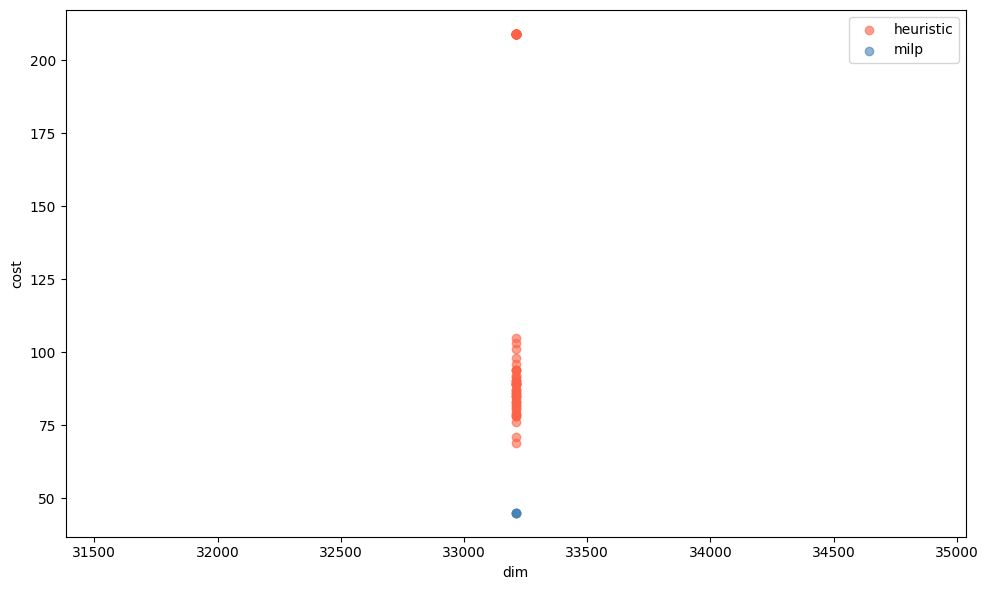

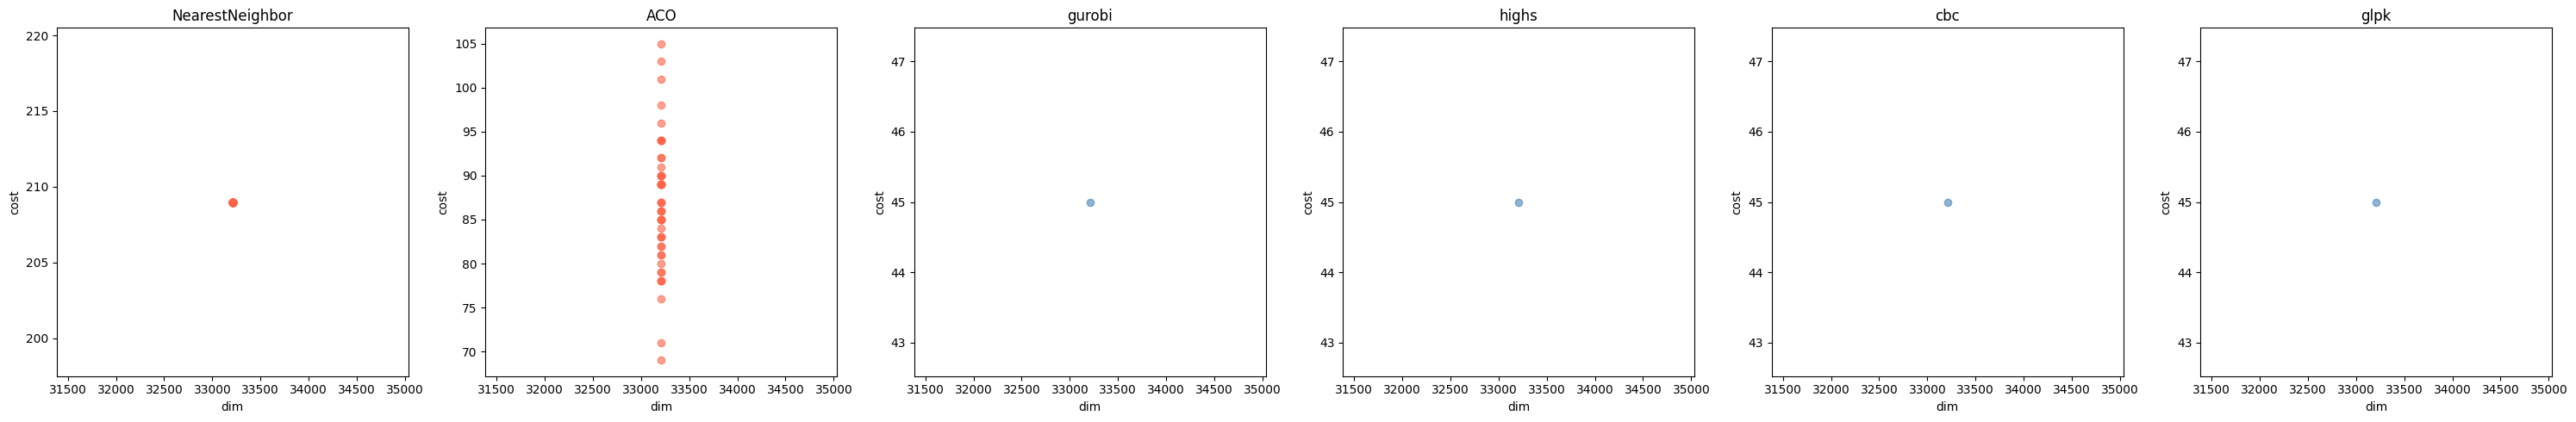

In [28]:
df_f = df[(df['c'] == 10) & (df['v'] == 10)]

cost_threshold = 100000
# Grafico combinado
fig, ax = plt.subplots(figsize=(10, 6))

for solver in df_f["solver"].unique():
    group = df_f[(df_f["solver"] == solver) & (df_f["dim"] < threshold)]
    color = "steelblue" if solver in milp_solvers else "tomato"
    label = "milp" if solver in milp_solvers else "heuristic"
    ax.scatter(group["dim"], group["cost"], color=color, label=label, alpha=0.6)

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))

ax.legend(by_label.values(), by_label.keys())
ax.set_xlabel("dim")
ax.set_ylabel("cost")
plt.tight_layout()
plt.show()

# Grafico por solver
solvers = df_f["solver"].unique()
n = len(solvers)

fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))

for ax, solver in zip(axes, solvers):
    group = df_f[(df_f["solver"] == solver) & (df_f["dim"] < threshold)]
    color = "steelblue" if solver in milp_solvers else "tomato"
    ax.scatter(group["dim"], group["cost"], alpha=0.6, color=color)
    ax.set_title(solver)
    ax.set_xlabel("dim")
    ax.set_ylabel("cost")


plt.tight_layout()
plt.show()

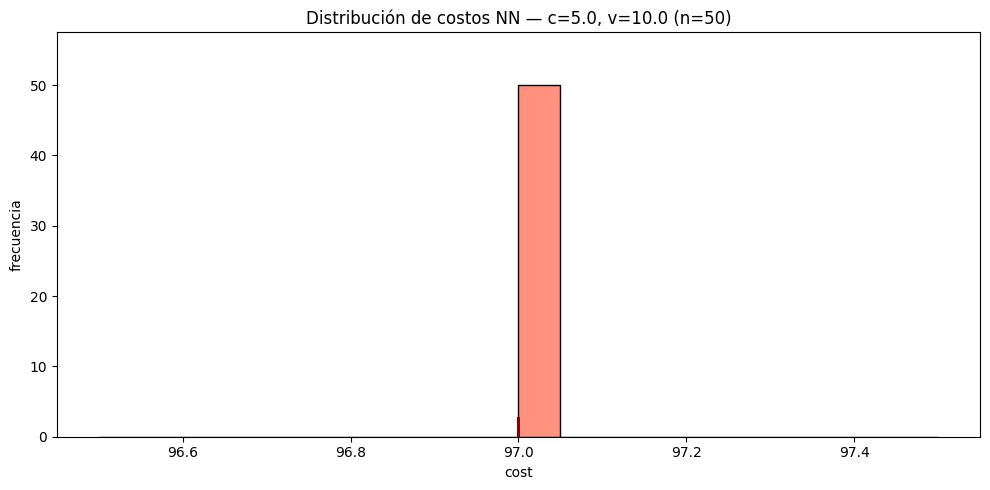

v     c   
5.0   5.0     1
      6.0     1
      7.0     1
      8.0     1
      9.0     1
             ..
75.0  25.0    1
80.0  5.0     1
      10.0    1
      15.0    1
      20.0    1
Name: cost, Length: 291, dtype: int64


In [29]:
c_val = df['c'].mode()[0]
v_val = df['v'].mode()[0]

group = df[(df["solver"] == "NearestNeighbor") & (df["c"] == c_val) & (df["v"] == v_val)]

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(group["cost"], bins=20, ax=ax, color="tomato", alpha=0.7)
sns.rugplot(group["cost"], ax=ax, color="darkred", height=0.05)

ax.set_title(f"Distribución de costos NN — c={c_val}, v={v_val} (n={len(group)})")
ax.set_xlabel("cost")
ax.set_ylabel("frecuencia")
plt.tight_layout()
plt.show()

combos = df[df["solver"] == "NearestNeighbor"].groupby(["v", "c"])["cost"].nunique()
print(combos)

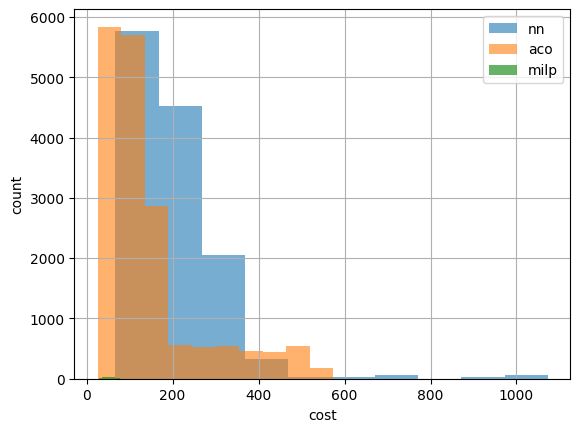

In [ ]:
df[df['solver'] == 'NearestNeighbor']['cost'].hist(alpha=0.6, label='nn')
df[df['solver'] == 'ACO']['cost'].hist(alpha=0.6, label='aco')
df[df['solver'] == 'glpk']['cost'].hist(alpha=0.6, color='green', label='milp')
plt.xlabel('cost')
plt.ylabel('count')
plt.legend()

A continuacion nos planeamos que pasaria si dejos correr ACO mas tiempo. Hay dos posibles escenarios, en uno ACO se queda en un minimo local y no llega a los resultados de milp y el otro es que con mas tiempo de ejecucion reduce significativamente el costo.

A su vez podemos realizar dos pruebas distinas, podemos corer distintas instancias de ACO en n segundo (1) o aumentar las iteraciones de aco para que la misma simulacion dure mas tiempo (2). Veamos cual de las dos opciones genera mejores resultados.

1. Notamos que con dejar correr varios ACOS distintos durante 100s, mejoramos un 20% el resultado de una simple corrida. Es mas, corriendo aco con un tiempo igual al avg(aco)*5 ya conseguimos buenos resultados
2. En cambio si dejamos correr la misma simulacion durante mas tiempo, llegamos a mejores resultado. Si bien siguen siendo bastante alejados de los resultados obtenidos por milp, estamos consumineod aproximadamente 1/6 del tiempo.

[C1] OK — demanda total=13, capacidad flota=1900.
[C2] OK — demanda por cliente={1}, Q_max=100.
[C3] OK — todas las ventanas tienen ei < li.
[C4] OK — todos li <= T_MAX=155.
[C5] OK — todos los clientes son alcanzables desde al menos un depot.
[C6] OK — todos los clientes pueden retornar a algún nodo de retorno.
[C7] Pares cliente-cliente alcanzables en tiempo: 156/156 (100.0%).
[C8] OK — vehículos disponibles=19, mínimo necesario=1.

  ✓  Instancia 'synthetic_n13_v19_seed42': pasa todas las verificaciones de factibilidad.

Budgets: {'1x ACO': '2.74s', '2x ACO': '5.49s', '5x ACO': '13.71s', 'MILP avg': '509.96s'}


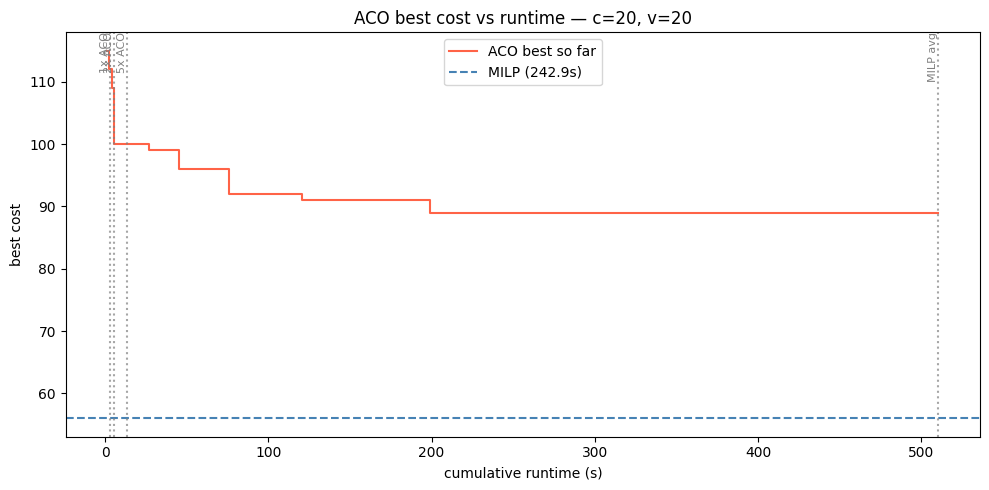

In [36]:
import time
import sys
sys.path.insert(0, '..')

from data.generators.synthetic import SyntheticGenerator
from solvers.aco import ACOSolver
from solvers.milp2a1 import MILPSolver

cfg_experiment = {
    'num_customers': 13,
    'num_vehicles': 19,
    'capacity': [100],
    'vehicle_penalty': 0,
    'customer_demand': 1,
    'seed': 42,
}
cfg_generator = {
    'cost_range': 'low',
    'tw_tightness': 'loose',
    'matrix_costs_ranges': {'low': [1, 20], 'high': [100, 200], 'high_dispersion': [1, 300]},
    'time_windows_tightness': {'loose': [0, 500], 'tight': [0, 20], 'critical': [0, 7]},
    'time_windows_values': [5, 10],
}

gen = SyntheticGenerator(cfg_experiment=cfg_experiment, cfg_generator=cfg_generator)
instance = gen.generate()

# Runtimes de referencia del df para c=20, v=20
avg_aco_ref  = df[(df['solver'] == 'ACO') & (df['c'] == 13) & (df['v'] == 19)]['runtime'].mean()
avg_milp_ref = df[(df['solver'].isin(milp_solvers)) & (df['c'] == 13) & (df['v'] == 19)]['runtime'].mean()

budgets = {
    '1x ACO':   avg_aco_ref,
    '2x ACO':   2 * avg_aco_ref,
    '5x ACO':   5 * avg_aco_ref,
    'MILP avg': avg_milp_ref,
}
print("Budgets:", {k: f"{v:.2f}s" for k, v in budgets.items()})

cfg_aco = {
    'num_ants': 100 if instance.CUSTOMERS <= 50 else 200,
    'num_iter': 100 if instance.CUSTOMERS <= 50 else 300,
    'alpha': 1.9, 'beta': 1.3, 'rho': 0.4,
    'lambda': 5, 'gamma': 2, 'penalty': 0,
    'phe': 100, 'tau_max': 10, 'tau_min': 1e-4,
  }

max_budget = max(budgets.values())
cumulative_time = 0
best_cost = float('inf')
history = []  # (cumulative_time, best_cost)

solver = ACOSolver(cfg_aco=cfg_aco)
while cumulative_time < max_budget:
    t0 = time.time()
    sol = solver.solve(instance)
    elapsed = time.time() - t0
    cumulative_time += elapsed
    if sol.feasible and sol.total_cost < best_cost:
        best_cost = sol.total_cost
    history.append((cumulative_time, best_cost))

# MILP para la misma instancia
milp = MILPSolver(cfg_milp={'solver': 'highs'})
t0 = time.time()
milp_sol = milp.solve(instance)
milp_runtime = time.time() - t0
milp_cost = milp_sol.total_cost if milp_sol.feasible else None

times, costs = zip(*history)

fig, ax = plt.subplots(figsize=(10, 5))
ax.step(times, costs, where='post', color='tomato', label='ACO best so far')

if milp_cost:
    ax.axhline(milp_cost, color='steelblue', linestyle='--', label=f'MILP ({milp_runtime:.1f}s)')

for label, budget in budgets.items():
    ax.axvline(budget, linestyle=':', color='gray', alpha=0.7)
    ax.text(budget, ax.get_ylim()[1], label, rotation=90, fontsize=8,
            va='top', ha='right', color='gray')

ax.set_xlabel('cumulative runtime (s)')
ax.set_ylabel('best cost')
ax.set_title('ACO best cost vs runtime — c=20, v=20')
ax.legend()
plt.tight_layout()
plt.show()

[C1] OK — demanda total=13, capacidad flota=1900.
[C2] OK — demanda por cliente={1}, Q_max=100.
[C3] OK — todas las ventanas tienen ei < li.
[C4] OK — todos li <= T_MAX=155.
[C5] OK — todos los clientes son alcanzables desde al menos un depot.
[C6] OK — todos los clientes pueden retornar a algún nodo de retorno.
[C7] Pares cliente-cliente alcanzables en tiempo: 156/156 (100.0%).
[C8] OK — vehículos disponibles=19, mínimo necesario=1.

  ✓  Instancia 'synthetic_n13_v19_seed42': pasa todas las verificaciones de factibilidad.

Budgets: {'1x ACO': '2.74s', '2x ACO': '5.49s', '5x ACO': '13.71s', 'MILP avg/2': '254.98s'}


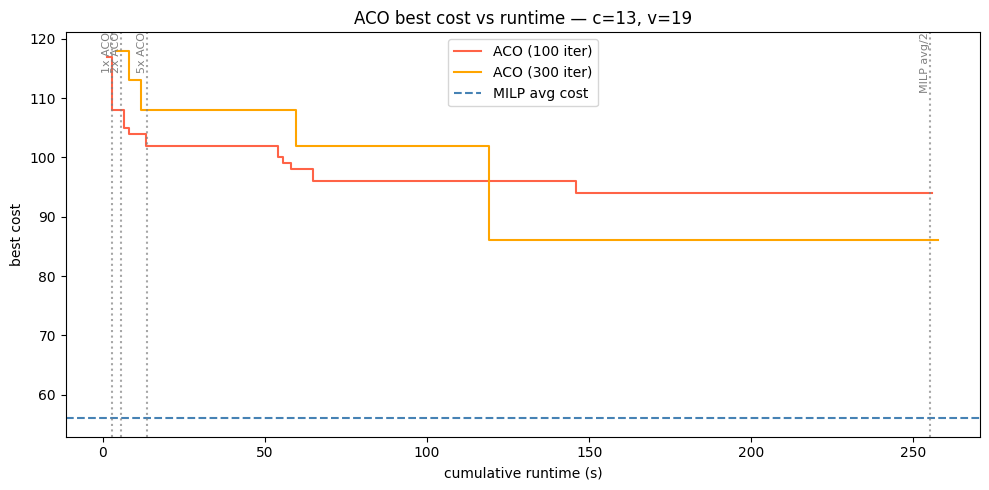

In [ ]:
import time
import sys
sys.path.insert(0, '..')

from data.generators.synthetic import SyntheticGenerator
from solvers.aco import ACOSolver

cfg_experiment = {
    'num_customers': 13,
    'num_vehicles': 19,
    'capacity': [100],
    'vehicle_penalty': 0,
    'customer_demand': 1,
    'seed': 42,
}
cfg_generator = {
    'cost_range': 'low',
    'tw_tightness': 'loose',
    'matrix_costs_ranges': {'low': [1, 20], 'high': [100, 200], 'high_dispersion': [1, 300]},
    'time_windows_tightness': {'loose': [0, 500], 'tight': [0, 20], 'critical': [0, 7]},
    'time_windows_values': [5, 10],
}

gen = SyntheticGenerator(cfg_experiment=cfg_experiment, cfg_generator=cfg_generator)
instance = gen.generate()

avg_aco_ref  = df[(df['solver'] == 'ACO') & (df['c'] == 13) & (df['v'] == 19)]['runtime'].mean()
avg_milp_ref = df[(df['solver'].isin(milp_solvers)) & (df['c'] == 13) & (df['v'] == 19)]['runtime'].mean()
milp_cost    = df[(df['solver'].isin(milp_solvers)) & (df['c'] == 13) & (df['v'] == 19)]['cost'].mean()

budgets = {
    '1x ACO':     avg_aco_ref,
    '2x ACO':     2 * avg_aco_ref,
    '5x ACO':     5 * avg_aco_ref,
    'MILP avg/2': avg_milp_ref / 2,
}
print("Budgets:", {k: f"{v:.2f}s" for k, v in budgets.items()})

def run_aco(instance, cfg_aco, max_budget):
    cumulative_time = 0
    best_cost = float('inf')
    history = []
    solver = ACOSolver(cfg_aco=cfg_aco)
    while cumulative_time < max_budget:
        t0 = time.time()
        sol = solver.solve(instance)
        elapsed = time.time() - t0
        cumulative_time += elapsed
        if sol.feasible and sol.total_cost < best_cost:
            best_cost = sol.total_cost
        history.append((cumulative_time, best_cost))
    return history

base_iters = 100 if instance.CUSTOMERS <= 50 else 300

cfg_aco_base = {
    'num_ants': 100 if instance.CUSTOMERS <= 50 else 200,
    'num_iter': base_iters,
    'alpha': 1.9, 'beta': 1.3, 'rho': 0.4,
    'lambda': 5, 'gamma': 2, 'penalty': 0,
    'phe': 100, 'tau_max': 10, 'tau_min': 1e-4,
}
cfg_aco_more = {**cfg_aco_base, 'num_iter': base_iters + 200}

max_budget = avg_milp_ref / 2
history_base = run_aco(instance, cfg_aco_base, max_budget)
history_more = run_aco(instance, cfg_aco_more, max_budget)

fig, ax = plt.subplots(figsize=(10, 5))

for history, label, color in [
    (history_base, f'ACO ({base_iters} iter)',        'tomato'),
    (history_more, f'ACO ({base_iters + 200} iter)',  'orange'),
]:
    times, costs = zip(*history)
    ax.step(times, costs, where='post', color=color, label=label)

ax.axhline(milp_cost, color='steelblue', linestyle='--', label=f'MILP avg cost')

for label, budget in budgets.items():
    ax.axvline(budget, linestyle=':', color='gray', alpha=0.7)
    ax.text(budget, ax.get_ylim()[1], label, rotation=90, fontsize=8,
            va='top', ha='right', color='gray')

ax.set_xlabel('cumulative runtime (s)')
ax.set_ylabel('best cost')
ax.set_title('ACO best cost vs runtime — c=13, v=19')
ax.legend()
plt.tight_layout()
plt.show()

se podria implementar un estimador que me diga: "si dejas correr x segundos de tiempo obtener soluciones 20% mejores"

In [35]:
df[(df['solver'].isin(milp_solvers)) & (df['c']==13)].groupby(['v']).size()

v
5.0     4
6.0     4
7.0     4
8.0     4
9.0     4
10.0    4
12.0    4
13.0    4
14.0    4
15.0    4
16.0    4
17.0    4
18.0    4
19.0    4
dtype: int64